# 5. Modelado con PySpark

El pipeline usa `FeatureHasher`, `StringIndexer` solo en baja cardinalidad, `VectorAssembler` y `StandardScaler`, con
`LogisticRegression`, `GBTClassifier` y `MultilayerPerceptronClassifier`. Corre en modo local con 8 núcleos y 14 GB de
heap: no hay clúster. La ejecución no usa UDF de Python (capítulo 3).

El punto central de este capítulo: **el MLP de Spark no pudo correr como pide el enunciado.**

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ctr.plots import C, style, es, miles
from ctr.config import RES
from ctr.monitor import read_jsonl
style()
pd.set_option("display.max_columns", 30)
S = pd.DataFrame(read_jsonl(RES / "spark" / "runs.jsonl"))
G = pd.DataFrame(read_jsonl(RES / "spark" / "grid.jsonl"))
G["capas"] = G.layers.map(lambda l: "[" + ", ".join(map(str, l)) + "]")

## 5.1 El límite de memoria del MLP de Spark

Spark representa `FeatureHasher` como vector disperso, lo que hace pensar que `d = 2^14` es barato. No lo es en este
clasificador. `DataStacker` en `ml/ann/Layer.scala` copia cada fila a un arreglo denso de `d + 2` valores por fila, y
`FeedForwardTrainer` lo persiste con `MEMORY_AND_DISK`:

```scala
val bigVector = new Array[Double](inputSize * size + outputSize * size)  // Layer.scala, Spark 4.0.1
...
if (handlePersistence) trainData.persist(StorageLevel.MEMORY_AND_DISK)
```

Así, la memoria necesaria es `n x (d + 2) x 8` bytes. Con `d = 2^14` cada fila ocupa 131 KB, contra unos 400 bytes si
siguiera dispersa. Los 32 millones de filas necesitarían 3,9 TB. Se midió qué tan lejos se llega con 14 GB de heap:

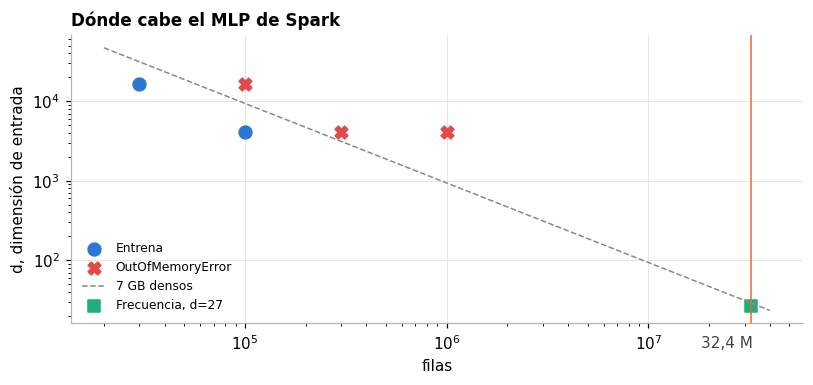

,n,d,GB densos,Resultado,seg,AUC día 29
0,100110,4100,3.060,Entrena,49.246,0.637
1,29849,16388,3.645,Entrena,107.901,0.661
2,299126,4100,9.142,OutOfMemoryError,8.492,NaN
3,100110,16388,12.225,OutOfMemoryError,10.867,NaN
4,999123,4100,30.535,OutOfMemoryError,10.465,NaN


In [2]:
m = S[S.exp == "map"].copy()
m["Resultado"] = m.status.map(lambda x: "Entrena" if x == "ok" else "OutOfMemoryError")
tb = m[["n", "d", "dense_gb", "Resultado", "fit_sec", "v_auc"]].rename(columns={"dense_gb": "GB densos", "fit_sec": "seg", "v_auc": "AUC día 29"}).round(3).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for ok, co, mk, lb in [(True, C["azul"], "o", "Entrena"), (False, C["rojo"], "X", "OutOfMemoryError")]:
    d = m[(m.status == "ok") == ok]
    ax.scatter(d.n, d.d, color=co, marker=mk, s=70, label=lb)
xs = np.geomspace(2e4, 4e7, 50)
ax.plot(xs, 7 * 1024**3 / (8 * xs), color=C["gris"], ls="--", lw=1, label="7 GB densos")
ax.axvline(32377421, color=C["naranja"], lw=1); ax.text(3.3e7, 8, "32,4 M", color="#444", ha="right")
ax.scatter([32377421], [27], color=C["aqua"], marker="s", s=60, label="Frecuencia, d=27")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set(title="Dónde cabe el MLP de Spark", xlabel="filas", ylabel="d, dimensión de entrada"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
tb

Con menos del 1 % de los datos (300 mil filas) y la dimensión menor del enunciado, el clasificador falla. Las capas `[d,
...]` con `d = 2^14` de la guía solo corren aquí con 30 mil filas. La frontera observada queda entre 3,6 y 9 GB densos:
el heap también tiene que cargar el resto del trabajo, y la lectura del código anticipa que más memoria solo mueve la
frontera, porque el costo crece linealmente con `n x d`.

El enunciado advierte que one-hot sobre `device_ip` es inviable. Este resultado extiende esa advertencia: **el hashing
no resuelve el problema en el MLP de Spark**, porque la densificación ocurre después.

### Consecuencia para el diseño

Para usar los datos completos hay que achicar `d`. Se probaron dos salidas:

- **Frecuencia** (`d = 27`): cabe entera, pero borra la identidad de las categorías.
- **Hashing pequeño** (`d = 2^9 + 4`): cabe con 1 millón de filas, con colisiones fuertes.

## 5.2 Rejilla con ParamGridBuilder

`TrainValidationSplit` y `CrossValidator` parten al azar, lo que rompe el protocolo temporal. La rejilla se construye con
`ParamGridBuilder`, igual que en el enunciado, pero cada `ParamMap` se ajusta con entrenamiento y se evalúa con
`BinaryClassificationEvaluator` en el día 29.

La rejilla completa (4 capas × 2 `stepSize` × 2 `maxIter` × 2 `solver`, 32 combinaciones) corrió con frecuencia y 200
mil filas. Con hashing `d = 2^10` y 100 mil filas solo corrieron las 4 capas con `l-bfgs` y 50 iteraciones: cada
combinación completa habría costado decenas de minutos.

In [3]:
c = G[G.tag == "completa"]
p = c.groupby(["capas", "solver"]).auc.max().unstack().round(4)
p["seg (l-bfgs)"] = c[c.solver == "l-bfgs"].groupby("capas").sec.mean().round(0)
display(p.loc[sorted(p.index, key=len)])
display(c.sort_values("auc", ascending=False).head(4)[["capas", "stepSize", "maxIter", "solver", "auc", "sec"]].round(4).reset_index(drop=True))
h = G[G.tag == "lbfgs"][["capas", "d", "n", "auc", "sec", "gb"]].round(4).reset_index(drop=True)
h

solver,gd,l-bfgs,seg (l-bfgs)
capas,,,
"[27, 10, 2]",0.5445,0.6178,27.0
"[27, 50, 2]",0.5815,0.6586,33.0
"[27, 100, 2]",0.5918,0.6534,58.0
"[27, 128, 64, 2]",0.5527,0.6753,137.0


,capas,stepSize,maxIter,solver,auc,sec
0,"[27, 128, 64, 2]",0.10,200,l-bfgs,0.6753,189.3714
1,"[27, 128, 64, 2]",0.01,200,l-bfgs,0.6724,171.7627
2,"[27, 128, 64, 2]",0.01,100,l-bfgs,0.6621,92.1744
3,"[27, 128, 64, 2]",0.10,100,l-bfgs,0.6599,93.6873


,capas,d,n,auc,sec,gb
0,"[1028, 10, 2]",1028,100110,0.6610,24.4584,8.2197
1,"[1028, 50, 2]",1028,100110,0.7089,40.6483,8.2180
2,"[1028, 100, 2]",1028,100110,0.7086,63.4976,8.1995
3,"[1028, 128, 64, 2]",1028,100110,0.5576,705.3557,8.3492


Tres lecturas de la rejilla:

- **`l-bfgs` domina a `gd`** en todas las arquitecturas, por 0,05 a 0,12 de AUC. Con sigmoide y descenso por lotes
  completos, `gd` apenas avanza en 100 o 200 pasos.
- **`stepSize` casi no importa con `l-bfgs`:** solo lo usa `gd`.
- **Más capacidad ayuda,** de `[27, 10, 2]` (0,618) a `[27, 128, 64, 2]` (0,675), con el costo multiplicado por 5.

Aun la mejor combinación con frecuencia queda lejos de scikit-learn con la misma codificación (0,680 con 1 millón). Y el hashing
pequeño (`d = 2^10`, solo 100 mil filas) ya supera a la frecuencia con 200 mil filas: 0,709 con `[1028, 50, 2]`. Para el
MLP, la identidad de las categorías vale más que el volumen. Con hashing, la red profunda `[1028, 128, 64, 2]` no convergió
en 50 iteraciones (0,558) y tardó 12 minutos: más capas con sigmoide piden más pasos.

## 5.3 Repeticiones por semilla

In [4]:
s = S[(S.exp == "scale") & (S.status == "ok")].copy()
s["capas"] = s.layers.map(lambda l: "x".join(map(str, l)) if l else "-")
t = s.groupby(["model", "enc", "capas", "maxIter", "n"]).agg(semillas=("seed", "size"), AUC=("v_auc", "mean"), sd=("v_auc", "std"), logloss=("v_logloss", "mean"), ECE=("v_ece", "mean"), seg=("fit_sec", "mean"), prep=("prep_sec", "mean")).round(4).reset_index()
t

,model,enc,capas,maxIter,n,semillas,AUC,sd,logloss,ECE,seg,prep
0,gbt,gbt,-,50,100110,5,0.6992,0.0027,0.4007,0.0131,72.9315,96.3142
1,gbt,gbt,-,50,999123,2,0.7148,0.0013,0.3951,0.0159,129.3347,119.7028
2,lr,hash12,-,100,100110,1,0.7071,NaN,0.4061,0.0254,36.3921,80.4784
3,lr,hash12,-,100,999123,1,0.7300,NaN,0.3889,0.0149,37.2524,85.6781
4,mlp,freq,128x64,200,100110,5,0.6698,0.0040,0.4127,0.0264,68.6569,43.5780
5,mlp,freq,128x64,200,999123,1,0.6743,NaN,0.4092,0.0227,664.3447,77.0287
6,mlp,freq,50,100,100110,5,0.6687,0.0052,0.4108,0.0216,19.9642,49.7957
7,mlp,hash9,128x64,50,999123,1,0.7070,NaN,0.3980,0.0129,539.3627,81.0714
8,mlp,hash9,128x64,100,100110,5,0.7052,0.0010,0.3991,0.0105,87.6639,47.8511
9,mlp,hash9,128x64,200,100110,1,0.7067,NaN,0.4012,0.0203,378.1124,46.0551


**El mejor modelo de Spark no es el MLP.** La regresión logística con hash12 llega a 0,730 con 1 millón de filas en 37 s. Es mejor
que cualquier MLP de Spark (0,707 en el mejor caso) y que GBT (0,715). Con 32,4 millones se queda en 0,7305: más datos no la
mueven. La razón: es la única que puede usar `d = 4.100` sin densificar, porque trabaja con vectores dispersos.

**El MLP de Spark sí aprovecha el hashing, aunque sea pequeño.** Con 2^9 sube a 0,707 frente a 0,674 con frecuencia, en el mismo
millón de filas. Pero ese millón es el tope práctico: con 2^9, 3 millones ya serían 11,6 GB densos.

**Sobre las semillas:** con 100 mil filas, la desviación del MLP con frecuencia ronda 0,004 a 0,005, más del doble que en
scikit-learn. La regresión logística no depende de la semilla (l-bfgs determinista) y se corrió una vez. Con 1 millón y con
32,4 millones, varios casos tienen una sola corrida por costo: 9 a 11 minutos por ajuste del MLP en 1 millón, con otros
experimentos en paralelo. La variación por semilla de esos casos se estima con la de 100 mil filas.

## 5.4 Limitaciones del MLP de Spark

| Limitación | Efecto en este problema |
|---|---|
| Sin capas de embedding | Cada categoría entra por hashing o frecuencia. No hay representación aprendida de `site_id` ni de `device_model` |
| Sin dropout, ni L2 | Sin regularización. Solo `maxIter` controla el sobreajuste |
| Activación sigmoide en capas ocultas | Sin ReLU. Gradientes más pobres en redes profundas, y `gd` queda muy atrás de `l-bfgs` |
| Salida softmax con dos neuronas | Equivale a una salida logística, sin ventaja |
| Sin pesos de clase | `weightCol` no existe en este clasificador; hay que remuestrear |
| Densifica la entrada | El hallazgo de 5.1: el costo real es `n x d` |
| Sin lotes por defecto en la práctica | `l-bfgs` da una pasada completa por iteración. Con `gd` el avance por pasada es bajo |

La extensión opcional con `TorchDistributor` no se hizo: PyTorch no está instalado en `ml_venv`, y requiere Python
workers, que fallan en este Windows (capítulo 3).